# Hari 1, Sesi 5: Deret Waktu, Stasioneritas, Kointegrasi, dan ECM

**Durasi:** 75 menit

Alur berpikir yang harus terbawa:

1. Plot data dulu. Tren, siklus, dan lompatan struktural terlihat mata.
2. Uji akar unit (ADF). Kalau tidak stasioner di level, ambil selisih.
3. Kalau ada dua variabel yang sama-sama tidak stasioner, periksa
   kointegrasi sebelum meregresikan apa pun. Regresi dua variabel tren
   tanpa kointegrasi adalah regresi palsu (spurious).
4. Kalau terkointegrasi, pakai Error Correction Model (ECM).



**Posisi dalam alur workshop.** Sesi 1-4 memakai data cross-section.
Sesi ini menambahkan dimensi waktu, dari stasioneritas sampai ECM. Sesi
6 menutup dengan data panel dan GARCH.



## Persiapan: alamat data

Jalankan sel alamat data di bawah. `URL_DATA` menyimpan alamat folder CSV di GitHub;
`pd.read_csv(...)` membaca tabel sesuai nama CSV pada sel kode berikutnya.
Gunakan koneksi internet dan jalankan sel berurutan dengan **Shift + Enter**.



**Alur sesi:** kita menggunakan urutan waktu dan pengamatan berulang. Mulai dari tabel **Kenali data**, amati grafik, jalankan model, lalu jelaskan hasilnya dengan kata sendiri. Fokus visual sesi ini adalah perbedaan data aktual, ramalan, dan pola antarunit.

In [1]:
URL_DATA = "https://raw.githubusercontent.com/akhiyarwaladi/ekonometrika_coding_workshop/main/data/"

print("Alamat data siap. Jalankan sel pembacaan CSV berikutnya.")


Alamat data siap. Jalankan sel pembacaan CSV berikutnya.


<!-- kamus_variabel:ts_inflasi.csv -->

### Kenali data: Deret harga/inflasi simulasi

**Data:** `data/ts_inflasi.csv`. **Satu baris:** satu urutan periode simulasi; bukan tanggal kalender.

| Variabel/kolom | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|
| `obs` | Urutan waktu pengamatan. | 1, 2, 3, ...; frekuensi kalender tidak dirinci | Penanda waktu |
| `inflasi` | Deret level bertendensi naik, dicontohkan sebagai IHK pada sumber. | Level/indeks simulasi; bukan otomatis persen inflasi | Deret yang dianalisis |

Nomor obs tidak menunjukkan tanggal/bulan/tahun tertentu. Angka level dan perubahan persennya harus dibedakan.

Sumber definisi: [rujukan data](https://paggalih.github.io/matkul/sem2025-01/ekonometrika/).


In [2]:
import pandas as pd
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette=["#2F5D50", "#C15937", "#D9A441", "#5B8A8F"])
plt.rcParams.update({"figure.dpi": 150, "axes.titleweight": "bold", "font.size": 11})

inflasi = pd.read_csv(URL_DATA + "ts_inflasi.csv")

inflasi.head()

,obs,inflasi
0,1,100.5
1,2,101.2
2,3,101.8
3,4,102.5
4,5,103.1


**Baca tabel:** setiap baris adalah satu pengamatan dan setiap kolom adalah satu variabel. Cocokkan nama serta satuannya dengan tabel **Kenali data** sebelum membuat kolom turunan atau memasang model.

<!-- kamus_variabel:ts_saham.csv -->

### Kenali data: Harga saham simulasi

**Data:** `data/ts_saham.csv`. **Satu baris:** satu urutan periode simulasi; bukan tanggal kalender.

| Variabel/kolom | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|
| `obs` | Urutan waktu pengamatan. | 1, 2, 3, ...; frekuensi kalender tidak dirinci | Penanda waktu |
| `saham` | Deret harga saham simulasi untuk uji stasioneritas dan peramalan. | Level harga; skala uang tidak dirinci | Deret yang dianalisis |

Nomor obs tidak menunjukkan tanggal/bulan/tahun tertentu. Angka level dan perubahan persennya harus dibedakan.

Sumber definisi: [rujukan data](https://paggalih.github.io/matkul/sem2025-01/ekonometrika/).


In [3]:
saham_ts = pd.read_csv(URL_DATA + "ts_saham.csv")

saham_ts.head()

,obs,saham
0,1,5000
1,2,5050
2,3,5025
3,4,5100
4,5,5080


**Baca tabel:** setiap baris adalah satu pengamatan dan setiap kolom adalah satu variabel. Cocokkan nama serta satuannya dengan tabel **Kenali data** sebelum membuat kolom turunan atau memasang model.

<!-- kamus_variabel:ts_gdp_growth.csv -->

### Kenali data: Pertumbuhan ekonomi simulasi

**Data:** `data/ts_gdp_growth.csv`. **Satu baris:** satu urutan periode simulasi; bukan tanggal kalender.

| Variabel/kolom | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|
| `obs` | Urutan waktu pengamatan. | 1, 2, 3, ...; frekuensi kalender tidak dirinci | Penanda waktu |
| `gdp_growth` | GDP growth: laju pertumbuhan Produk Domestik Bruto. | Persen dalam konteks pertumbuhan | Deret yang dianalisis |

Nomor obs tidak menunjukkan tanggal/bulan/tahun tertentu. Angka level dan perubahan persennya harus dibedakan.

Sumber definisi: [rujukan data](https://paggalih.github.io/matkul/sem2025-01/ekonometrika/).


In [4]:
gdp = pd.read_csv(URL_DATA + "ts_gdp_growth.csv")

gdp.head()

,obs,gdp_growth
0,1,5.1
1,2,5.3
2,3,5.5
3,4,5.8
4,5,6.0


**Baca tabel:** setiap baris adalah satu pengamatan dan setiap kolom adalah satu variabel. Cocokkan nama serta satuannya dengan tabel **Kenali data** sebelum membuat kolom turunan atau memasang model.

<!-- kamus_variabel:ts_kurs.csv -->

### Kenali data: Kurs simulasi

**Data:** `data/ts_kurs.csv`. **Satu baris:** satu urutan periode simulasi; bukan tanggal kalender.

| Variabel/kolom | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|
| `obs` | Urutan waktu pengamatan. | 1, 2, 3, ...; frekuensi kalender tidak dirinci | Penanda waktu |
| `kurs` | Nilai tukar simulasi yang mengalami perubahan level di tengah periode. | Level kurs; pasangan mata uang tidak dirinci sumber tabel | Deret yang dianalisis |

Nomor obs tidak menunjukkan tanggal/bulan/tahun tertentu. Angka level dan perubahan persennya harus dibedakan.

Kolom turunan berikut dibuat saat praktik; kolom ini belum ada pada CSV awal.

| Kolom turunan | Pengertian | Satuan/kode |
|---|---|---|
| `pasca` | Indikator perubahan level mulai pengamatan ke-25 pada contoh. | 1 jika obs ≥ 25; 0 sebelumnya |

Sumber definisi: [rujukan data](https://paggalih.github.io/matkul/sem2025-01/ekonometrika/).


In [5]:
kurs = pd.read_csv(URL_DATA + "ts_kurs.csv")

kurs.head()

,obs,kurs
0,1,14000
1,2,14010
2,3,14005
3,4,14020
4,5,14015


**Baca tabel:** setiap baris adalah satu pengamatan dan setiap kolom adalah satu variabel. Cocokkan nama serta satuannya dengan tabel **Kenali data** sebelum membuat kolom turunan atau memasang model.

In [6]:
timeline = inflasi.merge(saham_ts, on="obs").merge(gdp, on="obs").merge(kurs, on="obs")
timeline.head()



import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 150, "font.size": 11, "axes.labelsize": 11, "axes.titleweight": "bold", "legend.fontsize": 10})

## 1. Lihat dulu bentuk datanya

Empat tipe deret waktu, persis seperti empat kasus di Pertemuan 12: tren
naik terus (inflasi), jalan acak (saham), siklus naik-turun (pertumbuhan
ekonomi), dan patahan struktural (kurs).



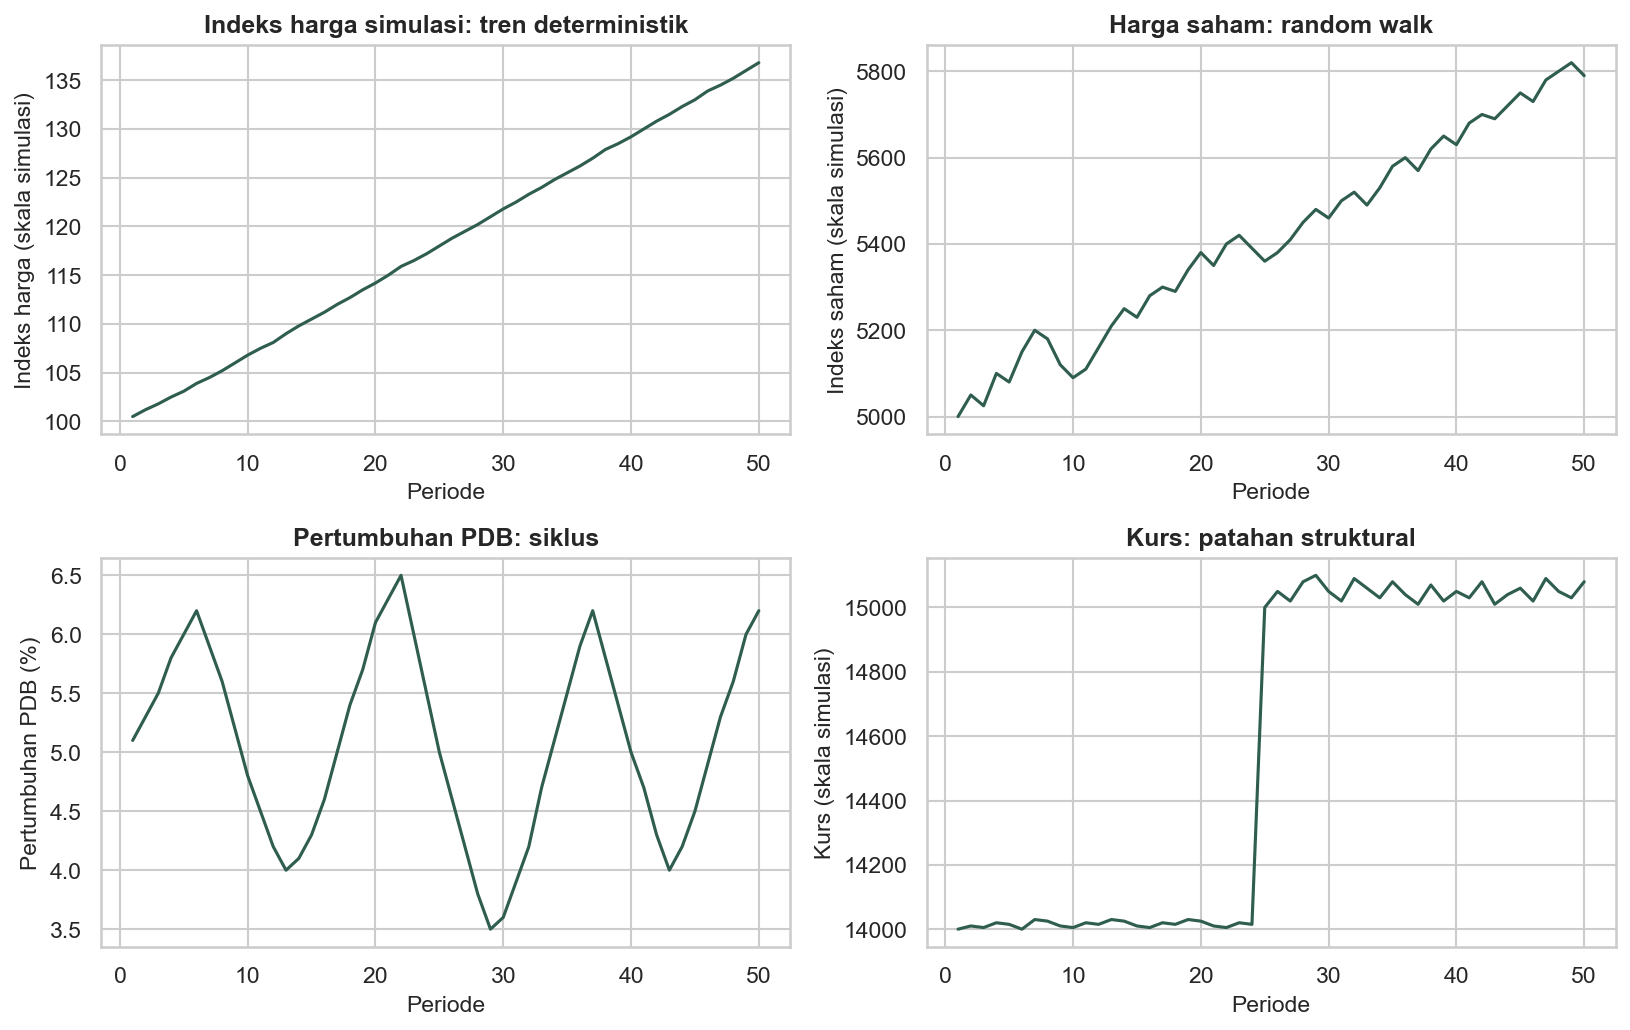

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
axes[0, 0].plot(timeline["obs"], timeline["inflasi"])
axes[0, 0].set_title("Indeks harga simulasi: tren deterministik")
axes[0, 1].plot(timeline["obs"], timeline["saham"])
axes[0, 1].set_title("Harga saham: random walk")
axes[1, 0].plot(timeline["obs"], timeline["gdp_growth"])
axes[1, 0].set_title("Pertumbuhan PDB: siklus")
axes[1, 1].plot(timeline["obs"], timeline["kurs"])
axes[1, 1].set_title("Kurs: patahan struktural")
axes[0, 0].set(xlabel="Periode", ylabel="Indeks harga (skala simulasi)")
axes[0, 1].set(xlabel="Periode", ylabel="Indeks saham (skala simulasi)")
axes[1, 0].set(xlabel="Periode", ylabel="Pertumbuhan PDB (%)")
axes[1, 1].set(xlabel="Periode", ylabel="Kurs (skala simulasi)")
plt.tight_layout()
plt.show()


**Baca grafik sebelum lanjut:** Baca waktu dari kiri ke kanan dan cocokkan satuan sumbu Y. Cari perubahan tingkat, tren, dan periode bergejolak sebelum menafsirkan hasil model.

## 2. Uji akar unit (ADF)

Hipotesis nol ADF: data punya akar unit (tidak stasioner). p-value kecil
berarti data stasioner. Uji di level dulu, lalu setelah satu kali selisih
(first difference) kalau perlu.



In [8]:
from statsmodels.tsa.stattools import adfuller

# adfuller() mengeluarkan beberapa hasil; posisi [1] adalah p-value.
print("ADF pada level:")
print("Inflasi:", adfuller(timeline["inflasi"])[1])
print("Saham:", adfuller(timeline["saham"])[1])
print("Pertumbuhan GDP:", adfuller(timeline["gdp_growth"])[1])
print("Kurs:", adfuller(timeline["kurs"])[1])


ADF pada level:
Inflasi: 0.8191770819941557
Saham: 0.9763367409665188
Pertumbuhan GDP: 2.4704329207955347e-06
Kurs: 0.7589305163316186


C:\Users\MyPC PRO\AppData\Local\Temp\ipykernel_2076\496956570.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  print("Inflasi:", adfuller(timeline["inflasi"])[1])
C:\Users\MyPC PRO\AppData\Local\Temp\ipykernel_2076\496956570.py:6: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  print("Saham:", adfuller(timeline["saham"])[1])
C:\Users\MyPC PRO\AppData\Local\Temp\ipykernel

In [9]:
# diff() menghitung selisih dengan periode sebelumnya.
# dropna() membuang baris pertama yang belum mempunyai selisih.
print("ADF setelah selisih pertama:")
print("Inflasi:", adfuller(timeline["inflasi"].diff().dropna())[1])
print("Saham:", adfuller(timeline["saham"].diff().dropna())[1])
print("Pertumbuhan GDP:", adfuller(timeline["gdp_growth"].diff().dropna())[1])
print("Kurs:", adfuller(timeline["kurs"].diff().dropna())[1])


ADF setelah selisih pertama:
Inflasi: 4.0278022802180516e-05
Saham: 4.13033845081261e-08
Pertumbuhan GDP: 2.3284087700489836e-07
Kurs: 1.975123782631653e-09


C:\Users\MyPC PRO\AppData\Local\Temp\ipykernel_2076\1566506853.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  print("Inflasi:", adfuller(timeline["inflasi"].diff().dropna())[1])
C:\Users\MyPC PRO\AppData\Local\Temp\ipykernel_2076\1566506853.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  print("Saham:", adfuller(timeline["saham"].diff().dropna())[1])
C:\Users\MyP

Bacaan hasilnya: inflasi dan saham tidak stasioner di level, stasioner
setelah selisih. GDP growth sudah stasioner di level. Kurs tetap sulit
karena ada patahan; di bagian 5 kita tangani dengan dummy.



## 3. ACF dan PACF

Dua grafik ini membantu menebak orde AR (p) dan MA (q).



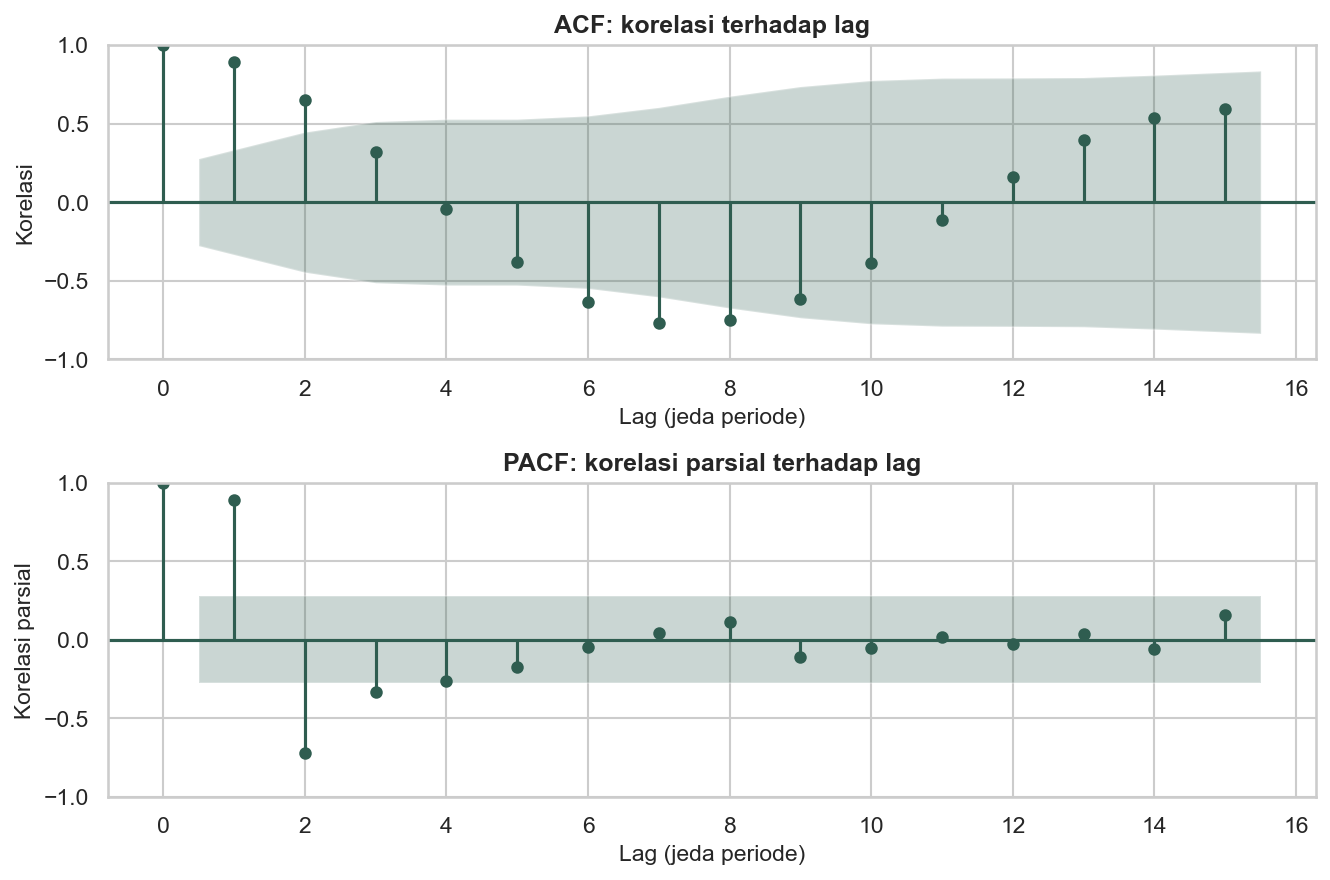

In [10]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(2, 1, figsize=(9, 6))
plot_acf(timeline["gdp_growth"], lags=15, ax=axes[0])
plot_pacf(timeline["gdp_growth"], lags=15, ax=axes[1])
axes[0].set(title="ACF: korelasi terhadap lag", xlabel="Lag (jeda periode)", ylabel="Korelasi")
axes[1].set(title="PACF: korelasi parsial terhadap lag", xlabel="Lag (jeda periode)", ylabel="Korelasi parsial")
plt.tight_layout()
plt.show()


**Baca grafik sebelum lanjut:** Sumbu mendatar menyatakan lag. Perhatikan pola beberapa lag sekaligus; ACF/PACF menjadi petunjuk awal yang tetap perlu diperiksa melalui model dan residual.

## 4. ARIMA: estimasi dan peramalan

Data GDP growth stasioner, jadi kita pakai ARIMA(p, 0, q). Untuk data yang
perlu satu kali selisih, d = 1.

Pemilihan orde: bandingkan AIC beberapa kandidat. Di bawah ini dipilih
otomatis yang terkecil.



In [11]:
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox

# Kita tetap membandingkan sembilan kandidat p=0..2 dan q=0..2.
# Tiga angka pada order adalah (p, d, q); d=0 karena seri ini stasioner.
model_000 = ARIMA(timeline["gdp_growth"], order=(0, 0, 0)).fit()
model_001 = ARIMA(timeline["gdp_growth"], order=(0, 0, 1)).fit()
model_002 = ARIMA(timeline["gdp_growth"], order=(0, 0, 2)).fit()
model_100 = ARIMA(timeline["gdp_growth"], order=(1, 0, 0)).fit()
model_101 = ARIMA(timeline["gdp_growth"], order=(1, 0, 1)).fit()
model_102 = ARIMA(timeline["gdp_growth"], order=(1, 0, 2)).fit()
model_200 = ARIMA(timeline["gdp_growth"], order=(2, 0, 0)).fit()
model_201 = ARIMA(timeline["gdp_growth"], order=(2, 0, 1)).fit()
model_202 = ARIMA(timeline["gdp_growth"], order=(2, 0, 2)).fit()


C:\Users\MyPC PRO\Documents\ekonometrika\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\MyPC PRO\Documents\ekonometrika\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


In [12]:
perbandingan = pd.DataFrame(
    {
        "orde": [
            (0, 0, 0),
            (0, 0, 1),
            (0, 0, 2),
            (1, 0, 0),
            (1, 0, 1),
            (1, 0, 2),
            (2, 0, 0),
            (2, 0, 1),
            (2, 0, 2),
        ],
        "AIC": [
            model_000.aic,
            model_001.aic,
            model_002.aic,
            model_100.aic,
            model_101.aic,
            model_102.aic,
            model_200.aic,
            model_201.aic,
            model_202.aic,
        ],
    }
)
urutan = perbandingan.sort_values("AIC")
print(urutan)


        orde         AIC
7  (2, 0, 1)  -40.984609
8  (2, 0, 2)  -39.147058
6  (2, 0, 0)  -35.850511
5  (1, 0, 2)   -8.061333
4  (1, 0, 1)    9.343914
2  (0, 0, 2)   29.234825
3  (1, 0, 0)   39.181028
1  (0, 0, 1)   69.157541
0  (0, 0, 0)  123.385686


In [13]:
# iloc[0] memilih baris pertama dari tabel yang sudah diurutkan.
orde_terbaik = urutan.iloc[0]["orde"]
p_terbaik = orde_terbaik[0]
q_terbaik = orde_terbaik[2]
print("Orde dengan AIC terkecil:", orde_terbaik)
model_terbaik = ARIMA(timeline["gdp_growth"], order=orde_terbaik).fit()
print(model_terbaik.summary())


Orde dengan AIC terkecil: (2, 0, 1)
                               SARIMAX Results                                
Dep. Variable:             gdp_growth   No. Observations:                   50
Model:                 ARIMA(2, 0, 1)   Log Likelihood                  25.492
Date:                Sat, 24 Oct 2026   AIC                            -40.985
Time:                        20:44:58   BIC                            -31.424
Sample:                             0   HQIC                           -37.344
                                 - 50                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          5.0451      0.075     67.365      0.000       4.898       5.192
ar.L1          1.8011      0.041     44.014      0.000       1.721       1.881
ar.L2         -0

In [14]:
lb = acorr_ljungbox(
    model_terbaik.resid, lags=[10], model_df=p_terbaik + q_terbaik, return_df=True
)
print("Ljung-Box: p > 0,05 berarti belum ada bukti autokorelasi sampai lag yang diuji.")
print(lb)


Ljung-Box: p > 0,05 berarti belum ada bukti autokorelasi sampai lag yang diuji.
     lb_stat  lb_pvalue
10  8.372339   0.300909


AIC memilih orde cukup tinggi di sini karena datanya siklus yang mulus.
Di data nyata, imbangi dengan prinsip parsimoni: kalau selisih AIC dua
model kurang dari 2, anggap seri dan pilih yang lebih sederhana.



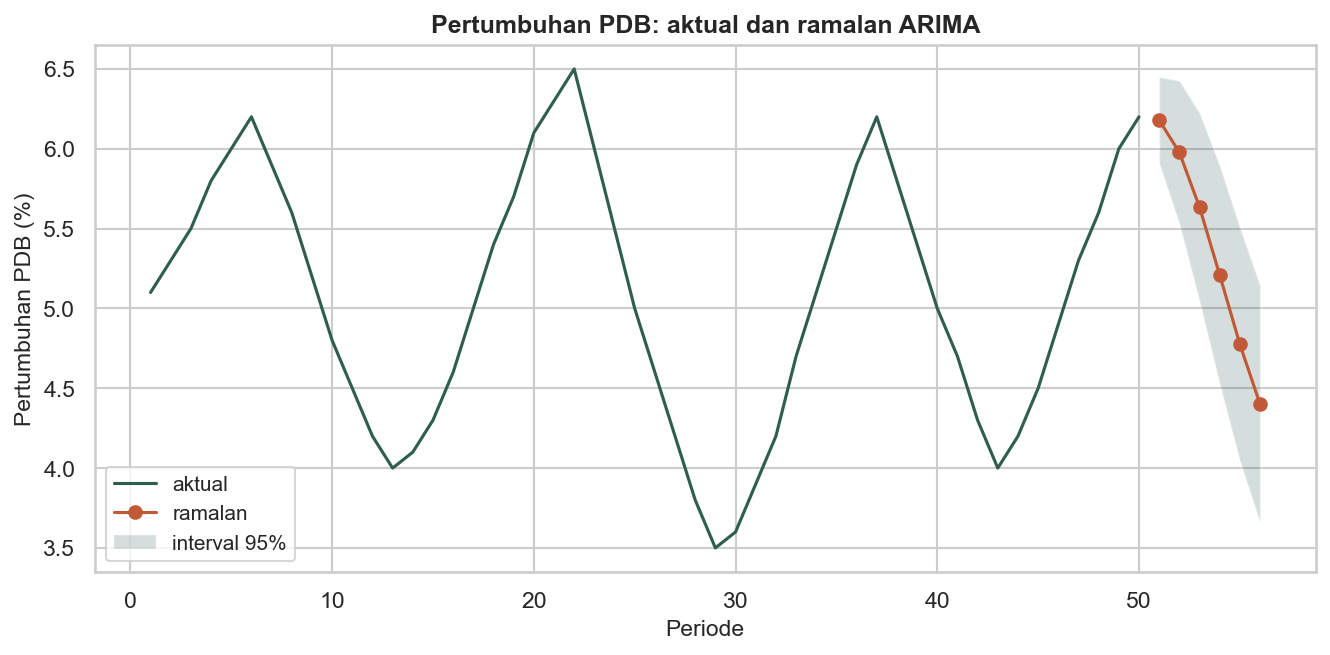

In [15]:
ramalan = model_terbaik.get_forecast(steps=6)
# conf_int() bisa mengembalikan DataFrame atau array tergantung versi
# statsmodels; disamakan jadi DataFrame supaya .iloc aman dipakai
batas = pd.DataFrame(ramalan.conf_int(alpha=0.05))

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(timeline["obs"], timeline["gdp_growth"], label="aktual")
masa_depan = np.arange(len(timeline) + 1, len(timeline) + 7)  # setelah periode 50
ax.plot(masa_depan, np.asarray(ramalan.predicted_mean), marker="o", label="ramalan")
ax.fill_between(
    masa_depan, batas.iloc[:, 0], batas.iloc[:, 1], alpha=0.2, label="interval 95%"
)
ax.legend()
ax.set_xlabel("Periode")
ax.set_ylabel("Pertumbuhan GDP")
plt.title("Pertumbuhan PDB: aktual dan ramalan ARIMA")
plt.ylabel("Pertumbuhan PDB (%)")
plt.tight_layout()
plt.show()


**Baca grafik sebelum lanjut:** Garis menunjukkan estimasi atau ramalan, sedangkan pita memperlihatkan rentang ketidakpastian yang dihitung model. Perhatikan batas periode data aktual dan periode yang diramal.

### Coba sendiri (5 menit)

Jalankan ARIMA(1, 0, 1) pada `gdp_growth` dan bandingkan AIC-nya
dengan tabel kandidat di atas.

Tulis di sel di bawah, baru buka jawabannya.



In [16]:
# Tulis kode Anda di sini


<details><summary>Lihat jawaban</summary>

Bandingkan AIC model_101 dengan tabel kandidat. Angka yang lebih kecil
lebih disukai. Tulis orde lengkap (p, d, q), misalnya (2, 0, 1),
supaya orde MA tidak tertukar dengan jumlah differencing.

</details>



## 5. Patahan struktural pada kurs

Kurs stabil di sekitar 14.000, lalu melonjak ke 15.000, lalu stabil lagi.
ADF tidak dirancang untuk pola begini. Cara praktis: uji dengan dummy
periode setelah patahan. Ini memeriksa pergeseran intersep pada tanggal
yang ditentukan, bukan uji Chow penuh untuk semua koefisien.



In [17]:
timeline["pasca"] = (timeline["obs"] >= 25).astype(int)
sampel_model_kurs = timeline[["kurs", "obs", "pasca"]].dropna()
X_model_kurs = sampel_model_kurs[["obs", "pasca"]]
y_model_kurs = sampel_model_kurs["kurs"]

model_kurs = LinearRegression()
model_kurs.fit(X_model_kurs, y_model_kurs)


LinearRegression()

### Lihat patahan kurs pada periode yang ditentukan

Dummy pasca membolehkan pergeseran tingkat kurs. Kita letakkan hasil prediksi pada urutan periode aslinya.

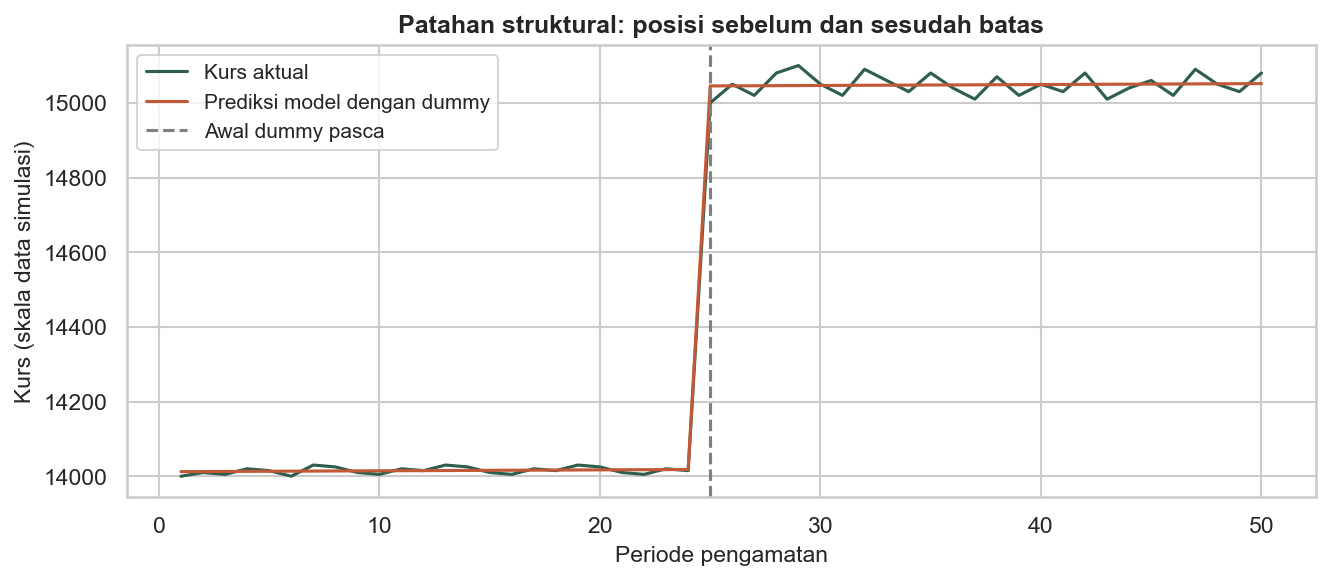

In [18]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(timeline["obs"], timeline["kurs"], label="Kurs aktual")
ax.plot(X_model_kurs["obs"], model_kurs.predict(X_model_kurs), label="Prediksi model dengan dummy")
ax.axvline(25, color="gray", linestyle="--", label="Awal dummy pasca")
ax.set_xlabel("Periode pengamatan")
ax.set_ylabel("Kurs (skala data simulasi)")
ax.set_title("Patahan struktural: posisi sebelum dan sesudah batas")
ax.legend()
plt.tight_layout()
plt.show()

**Cara membaca:** Batas periode berasal dari contoh, bukan hasil pencarian otomatis. Cocokkan pergeseran prediksi dengan koefisien dummy, lalu lanjutkan ke hubungan jangka panjang antarvariabel.

**Pelengkap statistik.** Model dan prediksinya sudah tersedia. Tabel berikut menambahkan standard error dan p-value pada sampel yang sama; gunakan penjelasan setelah tabel untuk memilih angka yang dibaca.

In [19]:
# Pelengkap statistik: standard error dan pengujian pada sampel yang sama.
uji_model_kurs = sm.OLS(
    y_model_kurs,
    sm.add_constant(X_model_kurs, has_constant="add").rename(
        columns={"const": "Intercept"}
    ),
).fit()
print(uji_model_kurs.summary())


                            OLS Regression Results                            
Dep. Variable:                   kurs   R-squared:                       0.998
Model:                            OLS   Adj. R-squared:                  0.998
Method:                 Least Squares   F-statistic:                 1.398e+04
Date:                Sat, 24 Oct 2026   Prob (F-statistic):           6.10e-66
Time:                        20:44:59   Log-Likelihood:                -223.57
No. Observations:                  50   AIC:                             453.1
Df Residuals:                      47   BIC:                             458.9
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   1.401e+04      6.955   2014.789      0.0

Kalau koefisien `pasca` besar dan signifikan, lompatan levelnya nyata.
Konsekuensinya untuk peramalan: jangan pakai satu garis tren lurus untuk
seluruh periode.



## 6. Kointegrasi: konsumsi dan pendapatan

Dua variabel yang sama-sama tidak stasioner bisa tetap punya hubungan
jangka panjang. Istilahnya kointegrasi. Analogi dari kuliah: pria mabuk
dan anjingnya yang diikat tali, jalan masing-masing acak, tapi tidak
pernah berpisah jauh.

Langkah uji Engle-Granger versi ringkas:
1. Regresikan Y pada X (persamaan jangka panjang).
2. Ambil residualnya.
3. Uji akar unit residual dengan nilai kritis Engle-Granger melalui `coint()`.
   Pastikan kedua seri berorde integrasi yang sama, umumnya I(1).



<!-- kamus_variabel:konsumsi_pendapatan.csv -->

### Kenali data: Konsumsi dan pendapatan runtun waktu

**Data:** `data/konsumsi_pendapatan.csv`. **Satu baris:** satu tahun berurutan pada data simulasi.

Nama singkat di kode berasal dari penggantian nama kolom CSV; isi angkanya tetap sama.

| Kolom CSV | Nama di kode | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|---|
| `Tahun` | `Tahun` | Nomor tahun dalam urutan simulasi, bukan tahun kalender. | 1, 2, 3, ... | Penanda waktu |
| `Konsumsi_Y` | `konsumsi` | Nilai konsumsi pada periode tersebut. | Skala uang tidak dirinci | Y: target |
| `Pendapatan_X` | `pendapatan` | Nilai pendapatan pada periode yang sama. | Skala uang tidak dirinci | X: penjelas |

Kolom turunan berikut dibuat saat praktik; kolom ini belum ada pada CSV awal.

| Kolom turunan | Pengertian | Satuan/kode |
|---|---|---|
| `ln_konsumsi` | Logaritma alami nilai konsumsi. | Skala logaritma |
| `ln_pendapatan` | Logaritma alami nilai pendapatan. | Skala logaritma |
| `d_konsumsi` | Selisih log konsumsi dari periode sebelumnya. | Perubahan log, belum dikalikan 100 |
| `d_pendapatan` | Selisih log pendapatan dari periode sebelumnya. | Perubahan log, belum dikalikan 100 |
| `ect` | Error Correction Term: penyimpangan dari hubungan jangka panjang pada periode sebelumnya. | Residual log periode sebelumnya |

Sumber definisi: [rujukan data](https://paggalih.github.io/matkul/sem2025-01/ekonometrika/).


In [20]:
makro = pd.read_csv(URL_DATA + "konsumsi_pendapatan.csv")
makro = makro.rename(columns={"Konsumsi_Y": "konsumsi", "Pendapatan_X": "pendapatan"})

makro.head()

,Tahun,konsumsi,pendapatan
0,1,100.5,120.2
1,2,102.1,122.5
2,3,104.3,125.1
3,4,103.8,124.8
4,5,106.5,128.4


**Baca tabel:** setiap baris adalah satu pengamatan dan setiap kolom adalah satu variabel. Cocokkan nama serta satuannya dengan tabel **Kenali data** sebelum membuat kolom turunan atau memasang model.

In [21]:
makro["ln_konsumsi"] = np.log(makro["konsumsi"])
makro["ln_pendapatan"] = np.log(makro["pendapatan"])

print("ADF level:")
print("ln(konsumsi):", adfuller(makro["ln_konsumsi"])[1])
print("ln(pendapatan):", adfuller(makro["ln_pendapatan"])[1])

sampel_model_lr = makro[["ln_konsumsi", "ln_pendapatan"]].dropna()
X_model_lr = sampel_model_lr[["ln_pendapatan"]]
y_model_lr = sampel_model_lr["ln_konsumsi"]

ADF level:
ln(konsumsi): 0.02318457311880574
ln(pendapatan): 0.012829928497885227


C:\Users\MyPC PRO\AppData\Local\Temp\ipykernel_2076\3078814807.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  print("ln(konsumsi):", adfuller(makro["ln_konsumsi"])[1])
C:\Users\MyPC PRO\AppData\Local\Temp\ipykernel_2076\3078814807.py:6: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  print("ln(pendapatan):", adfuller(makro["ln_pendapatan"])[1])


In [22]:
model_lr = LinearRegression()
model_lr.fit(X_model_lr, y_model_lr)

prediksi_model_lr = pd.Series(model_lr.predict(X_model_lr), index=y_model_lr.index)
residu_model_lr = y_model_lr - prediksi_model_lr


### Lihat hasil model: Log konsumsi

Di kiri, bandingkan nilai aktual dan prediksi. Di kanan, lihat residual, yaitu aktual dikurangi prediksi. Kedua panel memakai data latihan yang sama dengan model.

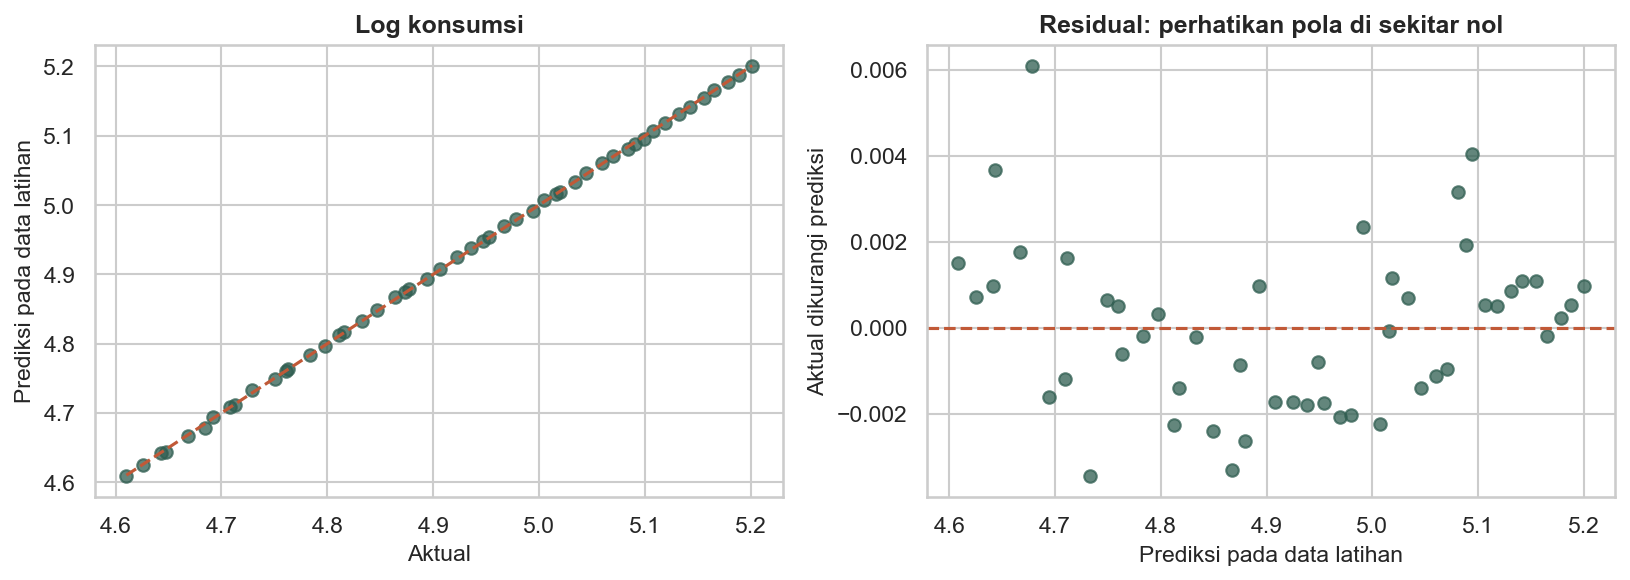

In [23]:
prediksi_visual = model_lr.predict(X_model_lr)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(y_model_lr, prediksi_visual, color="#2F5D50", alpha=0.75)
batas_visual = [y_model_lr.min(), y_model_lr.max()]
axes[0].plot(batas_visual, batas_visual, "--", color="#C15937")
axes[0].set(xlabel="Aktual", ylabel="Prediksi pada data latihan", title="Log konsumsi")
axes[1].scatter(prediksi_visual, y_model_lr - prediksi_visual, color="#2F5D50", alpha=0.75)
axes[1].axhline(0, color="#C15937", linestyle="--")
axes[1].set(xlabel="Prediksi pada data latihan", ylabel="Aktual dikurangi prediksi", title="Residual: perhatikan pola di sekitar nol")
plt.tight_layout()
plt.show()

**Cara membaca:** titik dekat diagonal mempunyai prediksi yang dekat aktual. Pada panel residual, cari pola melengkung atau lebar sebaran yang berubah. Kecocokan pada data latihan belum mengukur kemampuan memprediksi data baru. Sesudah membaca gambar, hubungkan pola itu dengan angka model dan pertanyaan latihannya.

**Pelengkap statistik.** Model dan prediksinya sudah tersedia. Tabel berikut menambahkan standard error dan p-value pada sampel yang sama; gunakan penjelasan setelah tabel untuk memilih angka yang dibaca.

In [24]:
# Pelengkap statistik: standard error dan pengujian pada sampel yang sama.
uji_model_lr = sm.OLS(
    y_model_lr,
    sm.add_constant(X_model_lr, has_constant="add").rename(
        columns={"const": "Intercept"}
    ),
).fit()
print("\n--- Persamaan jangka panjang ---")
print(uji_model_lr.summary())



--- Persamaan jangka panjang ---
                            OLS Regression Results                            
Dep. Variable:            ln_konsumsi   R-squared:                       1.000
Model:                            OLS   Adj. R-squared:                  1.000
Method:                 Least Squares   F-statistic:                 3.910e+05
Date:                Sat, 24 Oct 2026   Prob (F-statistic):           1.57e-95
Time:                        20:45:00   Log-Likelihood:                 242.08
No. Observations:                  50   AIC:                            -480.2
Df Residuals:                      48   BIC:                            -476.3
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept   

In [25]:
from statsmodels.tsa.stattools import coint

# Residual jangka panjang boleh digambar untuk melihat pola. Untuk keputusan
# kointegrasi, coint() memakai nilai kritis Engle-Granger yang sesuai.
# p-value ADF biasa pada residual hasil estimasi bukan penggantinya.

# Cara cepat dengan p-value langsung dari fungsi coint


**Batas contoh simulasi ini.** ADF dengan konstanta pada log kedua seri
memberi p sekitar 0,023 dan 0,013: akar unit sudah ditolak pada level.
Jadi hasil coint di bawah tidak cukup untuk menyatakan kedua seri I(1)
terkointegrasi. Perhitungan berikut memperagakan bentuk persamaan jangka
panjang dan komponen ECM, bukan bukti empiris kointegrasi yang sah.
Untuk penelitian, tetapkan tren/konstanta berdasarkan teori dan grafik,
periksa orde integrasi, lalu gunakan uji kointegrasi yang sesuai.



In [26]:
p_kointe = coint(makro["ln_konsumsi"], makro["ln_pendapatan"])[1]
print(f"Uji kointegrasi Engle-Granger: p = {p_kointe:.4f}")
print("Baca p-value ini bersama catatan orde integrasi pada data contoh.")


Uji kointegrasi Engle-Granger: p = 0.0001
Baca p-value ini bersama catatan orde integrasi pada data contoh.


Koefisien jangka panjang di atas (elastisitas konsumsi terhadap
pendapatan) hanya bisa dipercaya setelah kointegrasi terbukti. Tanpa itu,
R kuadrat tinggi pada dua variabel tren bisa menyesatkan.



### Coba sendiri (5 menit)

Uji kointegrasi untuk kasus lain: `data/ekspor_kurs.csv`.
Apakah ekspor dan kurs terkointegrasi?

Tulis di sel di bawah, baru buka jawabannya.



In [27]:
# Tulis kode Anda di sini


<details><summary>Lihat jawaban</summary>

`coint(ek["Ekspor_Y"], ek["Kurs_X"])` memberi p = 0,0016. Di bawah
0,05, jadi terkointegrasi. Bandingkan dengan IHSG-emas di Latihan yang
tidak terkointegrasi.

</details>



## 7. Error Correction Model (ECM)

Maksud ECM: perubahan jangka pendek Y dipengaruhi perubahan X, PLUS
koreksi dari ketidakseimbangan periode sebelumnya (ECT). ECT adalah
residual jangka panjang yang di-lag satu periode.

$$\Delta Y_t = \alpha_0 + \alpha_1 \Delta X_t + \gamma \, ECT_{t-1} + u_t$$

Syarat mutlak: koefisien $\gamma$ negatif dan signifikan. Nilainya
menunjukkan kecepatan penyesuaian.



In [28]:
makro["d_konsumsi"] = makro["ln_konsumsi"].diff()
makro["d_pendapatan"] = makro["ln_pendapatan"].diff()
makro["ect"] = residu_model_lr.shift(1)

sampel_model_ecm = makro[["d_konsumsi", "d_pendapatan", "ect"]].dropna()
X_model_ecm = sampel_model_ecm[["d_pendapatan", "ect"]]
y_model_ecm = sampel_model_ecm["d_konsumsi"]

model_ecm = LinearRegression()
model_ecm.fit(X_model_ecm, y_model_ecm)


LinearRegression()

### Lihat hasil model: Perubahan log konsumsi

Di kiri, bandingkan nilai aktual dan prediksi. Di kanan, lihat residual, yaitu aktual dikurangi prediksi. Kedua panel memakai data latihan yang sama dengan model.

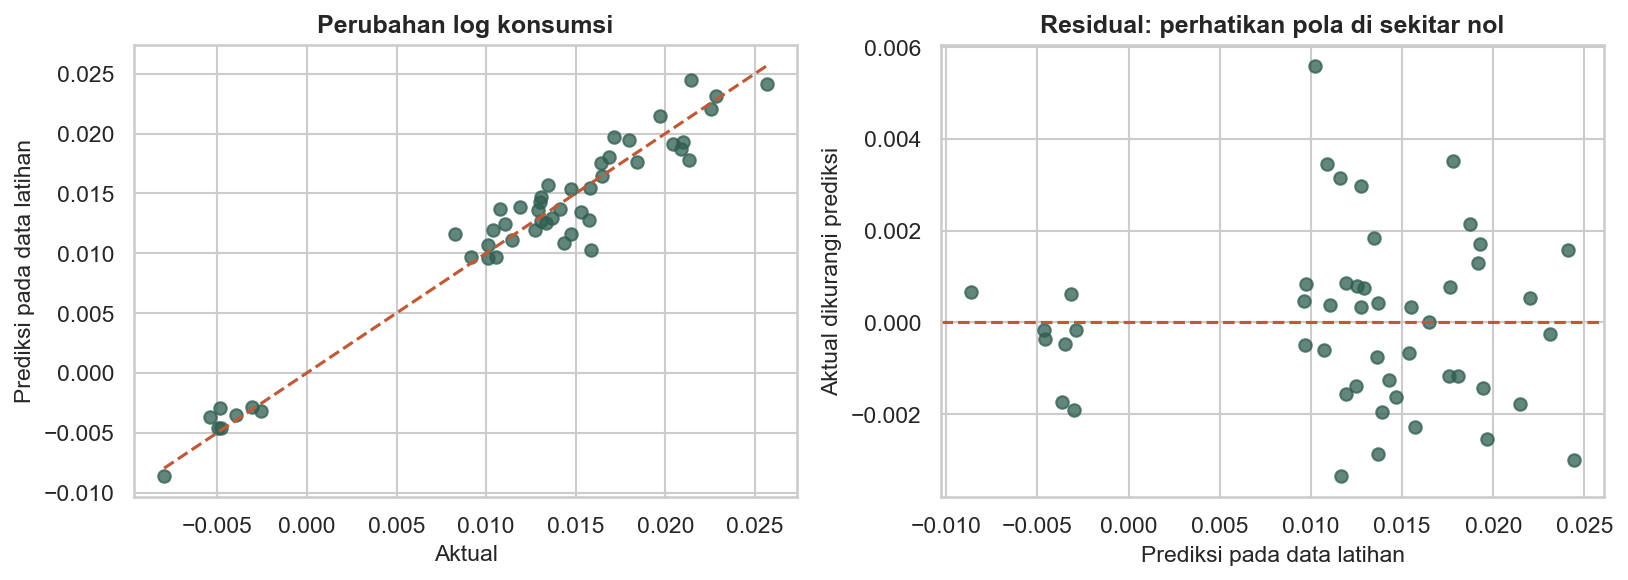

In [29]:
prediksi_visual = model_ecm.predict(X_model_ecm)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(y_model_ecm, prediksi_visual, color="#2F5D50", alpha=0.75)
batas_visual = [y_model_ecm.min(), y_model_ecm.max()]
axes[0].plot(batas_visual, batas_visual, "--", color="#C15937")
axes[0].set(xlabel="Aktual", ylabel="Prediksi pada data latihan", title="Perubahan log konsumsi")
axes[1].scatter(prediksi_visual, y_model_ecm - prediksi_visual, color="#2F5D50", alpha=0.75)
axes[1].axhline(0, color="#C15937", linestyle="--")
axes[1].set(xlabel="Prediksi pada data latihan", ylabel="Aktual dikurangi prediksi", title="Residual: perhatikan pola di sekitar nol")
plt.tight_layout()
plt.show()

**Cara membaca:** titik dekat diagonal mempunyai prediksi yang dekat aktual. Pada panel residual, cari pola melengkung atau lebar sebaran yang berubah. Kecocokan pada data latihan belum mengukur kemampuan memprediksi data baru. Sesudah membaca gambar, hubungkan pola itu dengan angka model dan pertanyaan latihannya.

**Pelengkap statistik.** Model dan prediksinya sudah tersedia. Tabel berikut menambahkan standard error dan p-value pada sampel yang sama; gunakan penjelasan setelah tabel untuk memilih angka yang dibaca.

In [30]:
# Pelengkap statistik: standard error dan pengujian pada sampel yang sama.
uji_model_ecm = sm.OLS(
    y_model_ecm,
    sm.add_constant(X_model_ecm, has_constant="add").rename(
        columns={"const": "Intercept"}
    ),
).fit()
print(uji_model_ecm.summary())


                            OLS Regression Results                            
Dep. Variable:             d_konsumsi   R-squared:                       0.952
Model:                            OLS   Adj. R-squared:                  0.950
Method:                 Least Squares   F-statistic:                     457.3
Date:                Sat, 24 Oct 2026   Prob (F-statistic):           4.42e-31
Time:                        20:45:01   Log-Likelihood:                 239.36
No. Observations:                  49   AIC:                            -472.7
Df Residuals:                      46   BIC:                            -467.0
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept     4.213e-05      0.000      0.086   

Baca tiga hal dari output:

1. Tanda dan signifikansi `ect`. Harus negatif dan p < 0,05.
2. Besarnya `ect` = kecepatan penyesuaian per periode. Nilai -0,70
   berarti 70 persen ketidakseimbangan dikoreksi tiap periode.
3. Koefisien `d_pendapatan` = elastisitas jangka pendek.



## Latihan

1. Jalankan uji kointegrasi dan ECM untuk kasus IHSG dan emas
   (`data/ihsg_emas.csv`). Apakah keduanya terkointegrasi? Kalau tidak,
   apakah ECM masih layak dipakai?
2. Ramalkan inflasi lima periode ke depan dengan ARIMA(1,1,0). Bandingkan
   dengan ramalan yang memakai d = 0. Perhatikan polanya: d = 0 menarik
   ramalan ke rata-rata, d = 1 meneruskan arah tren. Pilih yang sesuai
   perilaku data.
3. Kenapa ADF pada kurs gagal mendeteksi stasioneritas walaupun secara
   visual kurs terlihat "datar" di dua rezim? Hubungkan dengan konsep
   patahan struktural.



### Selanjutnya

Selanjutnya: Sesi 6 menutup Hari 1 dengan data panel dan GARCH.
